# DLENT-RT — theoretical (type / average) models over f

Loads `configs/v5_theory.yaml` (f = 0.5 and the dual rule for unseen types; the quota is fixed at the f = 1.25
fixed point, so every f has the same jobs),
shows the job distributions, then evaluates the type / average models for each f: fluid OPT (hindsight), fluid on
feasible types, the Phase 0 LP and its static policy on the real stream, and the fluid LP per window. The bucketed
MILP is run only if its matrix is small enough. No online model. The logic is in `dlent_rt/theory_eval.py`.
Build and run: `python notebooks/src/build.py 05_theory_models --execute`.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from dlent_rt.config import load_config
from dlent_rt import theory_eval as te
warnings.simplefilter("ignore")
pd.set_option("display.max_columns", 30, "display.width", 250)

cfg = load_config(ROOT / "configs" / "v5_theory.yaml")          # f = 0.5, policy.unseen_types = dual_rule
F_SCAN = (0.10, 0.20, 0.30, 0.50, 0.70, 1.25)

## 0. The theoretical models at f = 0.5 (summary)

From the cache of `scripts/week32/theory_f050.py` (`reports/week32/theory_f050_cache.pkl`; the 1-week bucketed
MILP behind the discretization cost takes up to an hour). Run that script first.

In [2]:
import pickle
with open(ROOT / "reports" / "week32" / "theory_f050_cache.pkl", "rb") as fh:
    F050 = pickle.load(fh)
with pd.option_context("display.max_colwidth", 200):
    display(F050["summary"].set_index("quantity"))
display(F050["milp"])

,value
quantity,
f,0.5
"C, CPU / RAM (machines)","1.737 / 1.156 (111 cores / 296 GB, declared 64 / 256)"
"tau, Phase 0 LP (CPU, RAM)","0.00206, 0.00162"
"tau, fluid OPT (CPU, RAM)","0.00210, 0.00169"
"windows with tau > 0, 1 day (CPU, RAM)","73.9%, 82.6%"
"windows with tau > 0, 6 h (CPU, RAM)","50.5%, 50.5%"
static policy (dual rule): time >= 95% full,24.1%
"static policy: mean occupancy / C (CPU, RAM)","79.3%, 78.9%"
static policy: jobs rejected for lack of space,4.97%


,run,jobs,candidates,nonzeros,tail checks,fluid OPT $,fluid feasible $,"fluid, volume inside the window $",MILP best $,MILP bound $,gap,discretization cost $ (best .. bound),cost %,fluid >= MILP best,fluid (inside window) >= MILP bound,MILP status,MILP s,LP relaxation s,MILP realised (job rewards) $
0,"day, f 0.5, tail checks","8,003","6,974","1,021,856",23,"1,297.59","1,297.59","1,689.94","1,456.42","1,461.49",0.35%,-158.83 .. -163.90,-12.24 .. -12.63,False,True,Time limit reached,900,1,"1,457.05"
1,"day, f 0.5, old","8,003","6,974","1,020,170",0,"1,297.59","1,297.59","1,689.94","1,452.33","1,461.86",0.66%,-154.74 .. -164.27,-11.93 .. -12.66,False,True,Time limit reached,900,1,"1,453.39"
2,"week, f 0.5, tail checks","59,985","53,214","9,267,322",22,"6,175.83","6,175.83","6,315.76","5,578.35","5,637.86",1.07%,597.47 .. 537.96,9.67 .. 8.71,True,True,Time limit reached,3603,14,"5,678.23"
3,"week, f 0.5, old","59,985","53,214","9,266,342",0,"6,175.83","6,175.83","6,315.76","5,563.36","5,638.57",1.35%,612.46 .. 537.26,9.92 .. 8.70,True,True,Time limit reached,3601,14,"5,659.30"
4,"week, f 0.3, tail checks","59,985","53,214","9,267,322",22,"4,491.03","4,491.03","4,715.05","3,619.86","4,188.98",15.72%,871.17 .. 302.05,19.40 .. 6.73,True,True,Time limit reached,901,35,"3,754.51"
5,"week, f 0.7, tail checks","59,985","53,214","9,267,322",22,"6,867.87","6,867.87","6,927.19","6,336.22","6,393.57",0.91%,531.65 .. 474.30,7.74 .. 6.91,True,True,Time limit reached,901,7,"6,367.64"


## 1. Job distributions (all 300k jobs and the jobs of H, before and after the 24 h cap and the quota)

In [3]:
J = te.job_distributions(cfg)
display(J["impact"])
display(J["dist"].round(4))

,set,jobs,CPU-hours (effective),jobs cut by the 24 h cap,share of jobs cut,CPU-hours cut by the cap,jobs removed by the quota,share of jobs removed,CPU-hours removed by the quota,CPU-hours left after both
0,all 300k,300000,187573.247128,901,0.003003,0.659093,5219,0.017397,0.970580,0.012994
1,H (first 7 days),47909,16185.888082,247,0.005156,0.460975,1313,0.027406,0.848086,0.036057


,set,stage,quantity,count,mean,p10,p25,p50,p75,p90,p95,p99,p99.9,max,w p10,w p25,w p50,w p75,w p90,w p95,w p99,w p99.9,w max
0,all 300k,before cap + quota,CPU request (machines),300000,0.1402,0.0025,0.0040,0.0080,0.0276,0.0623,0.0999,2.5115,23.0259,313.0679,4.9709,30.0373,77.7097,96.2996,272.5351,272.5351,313.0679,313.0679,313.0679
1,all 300k,before cap + quota,RAM request (machines),300000,0.0953,0.0016,0.0028,0.0065,0.0103,0.0237,0.0558,1.6544,15.7432,1469.6447,3.3055,12.9076,52.8039,64.8068,126.1807,126.1807,1469.6447,1469.6447,1469.6447
2,all 300k,before cap + quota,"duration, effective (h)",300000,0.4634,0.0058,0.0117,0.0219,0.0669,0.3150,0.7547,3.9748,73.8722,540.3553,8.6306,50.4740,117.4045,261.2901,261.3376,261.3376,336.3286,540.3073,540.3553
3,all 300k,before cap + quota,work r*d (machine-h),300000,0.6252,0.0000,0.0001,0.0002,0.0013,0.0060,0.0205,0.4218,18.1444,31128.3385,137.7166,1162.1151,20087.3511,25166.6964,31128.3385,31128.3385,31128.3385,31128.3385,31128.3385
4,all 300k,after cap + quota,CPU request (machines),294781,0.0234,0.0025,0.0039,0.0078,0.0247,0.0526,0.0811,0.2527,0.6945,0.8685,0.0109,0.0356,0.1537,0.4212,0.5996,0.6903,0.8439,0.8586,0.8685
5,all 300k,after cap + quota,RAM request (machines),294781,0.0128,0.0016,0.0028,0.0065,0.0096,0.0208,0.0339,0.1915,0.4523,0.5752,0.0046,0.0130,0.0896,0.2618,0.3839,0.4584,0.5261,0.5741,0.5752
6,all 300k,after cap + quota,"duration, effective (h)",294781,0.4371,0.0058,0.0117,0.0217,0.0656,0.3075,0.7406,3.9737,66.6661,540.3553,0.1815,1.0781,12.9272,28.0774,153.4899,242.9909,371.2737,540.3401,540.3553
7,all 300k,after cap + quota,duration after the 24 h cap (h),294781,0.2604,0.0167,0.0167,0.0217,0.0656,0.3075,0.7406,3.9737,24.0000,24.0000,0.1815,1.0781,12.9272,24.0000,24.0000,24.0000,24.0000,24.0000,24.0000
8,all 300k,after cap + quota,work r*d (machine-h),294781,0.0083,0.0001,0.0001,0.0003,0.0012,0.0045,0.0126,0.0934,1.1246,20.6061,0.0100,0.0814,0.8540,4.7200,12.4930,15.3614,16.9508,20.6061,20.6061
9,H (first 7 days),before cap + quota,CPU request (machines),47909,0.1572,0.0024,0.0039,0.0076,0.0196,0.0493,0.1843,4.1370,22.4930,67.6723,0.4750,1.7634,28.5443,67.6723,67.6723,67.6723,67.6723,67.6723,67.6723


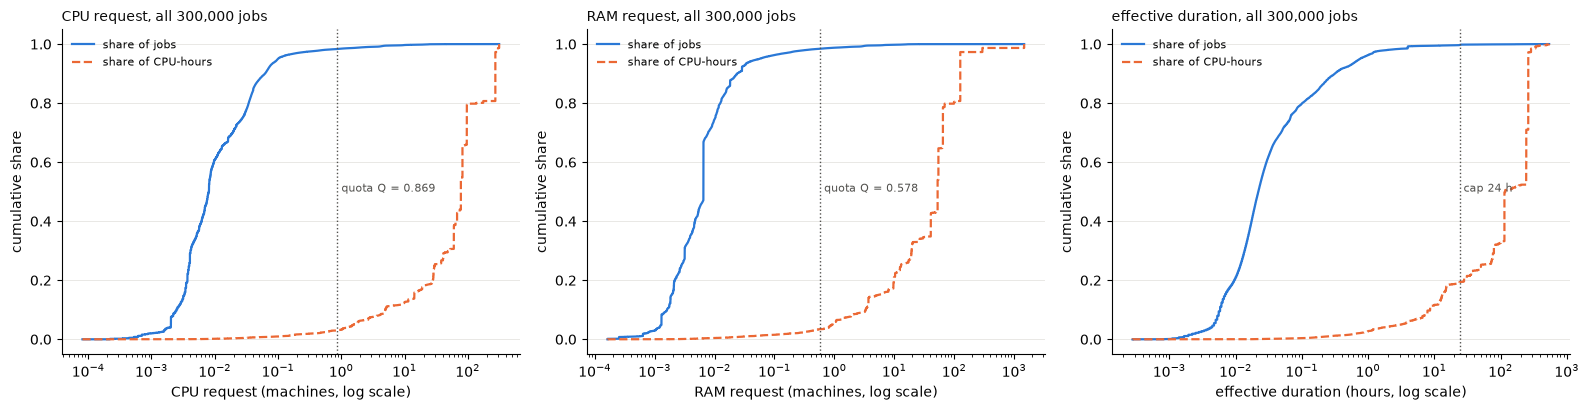

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, which in zip(axs, ("cpu", "ram", "duration")):
    te.fig_cdf_jobs_work(J, which, ax)
plt.tight_layout(); plt.show()

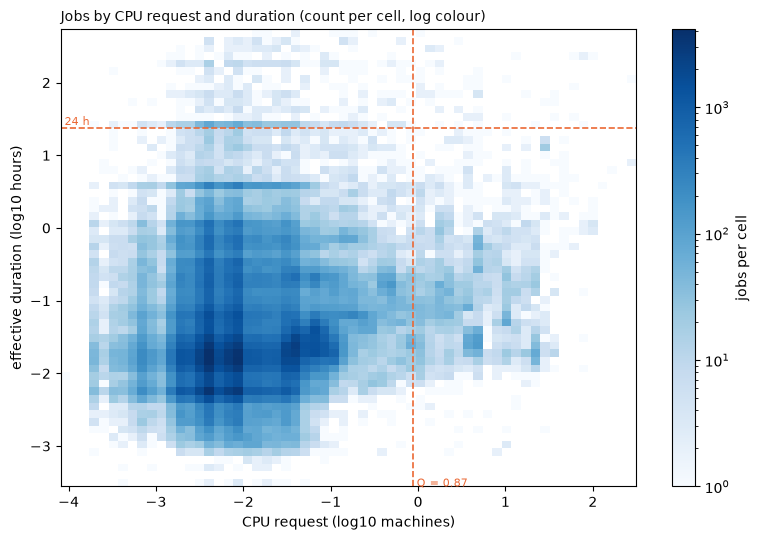

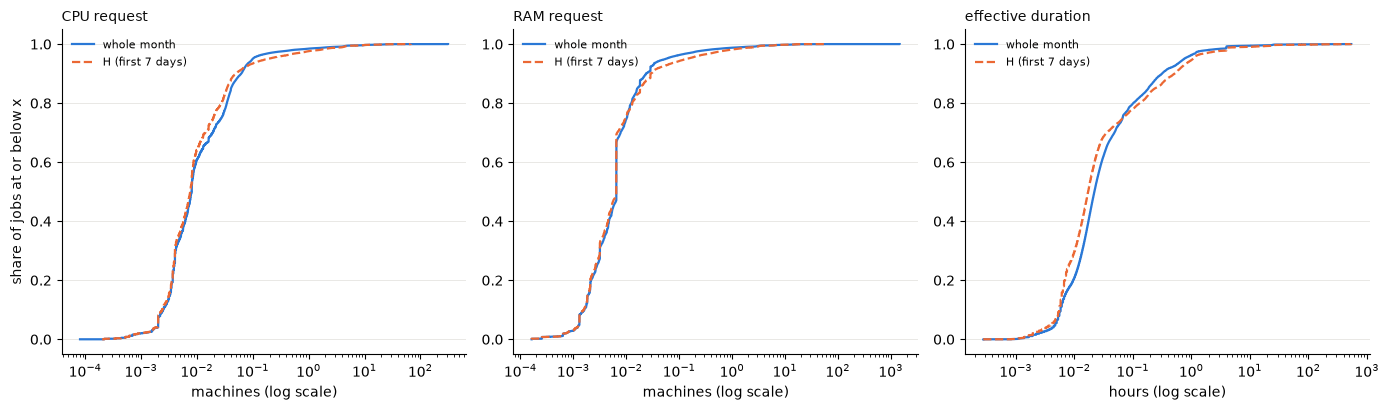

In [5]:
fig, ax = plt.subplots(figsize=(8, 5.5))
h = te.fig_hist2d(J, ax)
fig.colorbar(h[3], ax=ax, label="jobs per cell")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
te.fig_H_vs_month(J, axs)
plt.tight_layout(); plt.show()

## 2. Models for each f

In [6]:
R = [te.evaluate_f(cfg, f, seed=cfg.run.seed) for f in F_SCAN]
rows = []
for r in R:
    for key, lab in (("phase0_lp", "Phase 0 LP"), ("fluid", "fluid OPT"), ("fluid_feasible", "fluid feasible")):
        m = r[key]
        rows.append(dict(f=r["f"], LP=lab, C_cpu=r["C"][0], C_ram=r["C"][1], tau_cpu=m["tau"][0], tau_ram=m["tau"][1],
                         fully=m["counts"]["fully"], partly=m["counts"]["partly"], rejected=m["counts"]["rejected"],
                         fill_cpu=m["fill"][0], fill_ram=m["fill"][1]))
display(pd.DataFrame(rows).round(5))

,f,LP,C_cpu,C_ram,tau_cpu,tau_ram,fully,partly,rejected,fill_cpu,fill_ram
0,0.10,Phase 0 LP,0.34741,0.23126,0.00453,0.00539,176,2,3827,1.00000,1.00000
1,0.10,fluid OPT,0.34741,0.23126,0.00421,0.00377,362,2,5189,1.00000,1.00000
2,0.10,fluid feasible,0.34741,0.23126,0.00398,0.00352,426,2,4950,1.00000,1.00000
3,0.20,Phase 0 LP,0.69483,0.46252,0.00380,0.00358,467,2,3536,1.00000,1.00000
4,0.20,fluid OPT,0.69483,0.46252,0.00359,0.00308,648,2,4903,1.00000,1.00000
5,0.20,fluid feasible,0.69483,0.46252,0.00355,0.00301,673,2,4861,1.00000,1.00000
6,0.30,Phase 0 LP,1.04224,0.69379,0.00317,0.00296,779,2,3224,1.00000,1.00000
7,0.30,fluid OPT,1.04224,0.69379,0.00296,0.00282,982,2,4569,1.00000,1.00000
8,0.30,fluid feasible,1.04224,0.69379,0.00296,0.00282,982,2,4569,1.00000,1.00000
9,0.50,Phase 0 LP,1.73707,1.15631,0.00206,0.00162,1473,2,2530,1.00000,1.00000


In [7]:
rows = []
for r in R:
    for key, lab in te.MODELS:
        sp = r["phase0_lp"]["expected"] if key == "phase0_expected" else r[key]["split"]
        rows.append(dict(f=r["f"], model=lab, **{k: round(v, 1) for k, v in sp.items()}))
    b = r["bucketed"]
    rows.append(dict(f=r["f"], model="bucketed MILP", reward=b["split"]["reward"] if b["run"] else np.nan,
                     note="" if b["run"] else f"skipped: {b['nonzeros']:,} nonzeros"))
display(pd.DataFrame(rows))

,f,model,customer value,profit,carbon,reward,note
0,0.10,fluid OPT (hindsight),7265.0,1439.7,-2336.6,6368.1,NaN
1,0.10,fluid on feasible types,6785.3,1300.7,-2372.7,5713.4,NaN
2,0.10,"Phase 0 LP, expected",7916.7,1610.4,-2585.8,6941.3,NaN
3,0.10,"static Phase 0, realised",3486.2,430.6,-1922.1,1994.7,NaN
4,0.10,bucketed MILP,NaN,NaN,NaN,NaN,"skipped: 41,930,482 nonzeros"
5,0.20,fluid OPT (hindsight),13065.7,2391.3,-4730.5,10726.5,NaN
6,0.20,fluid on feasible types,12852.7,2318.6,-4744.3,10427.1,NaN
7,0.20,"Phase 0 LP, expected",14458.8,2881.2,-5051.9,12288.2,NaN
8,0.20,"static Phase 0, realised",7077.5,884.1,-3758.0,4203.7,NaN
9,0.20,bucketed MILP,NaN,NaN,NaN,NaN,"skipped: 41,930,482 nonzeros"


In [8]:
rows = []
for r in R:
    s = r["static"]
    w24, w6 = r["windows"][24], r["windows"][6]
    rows.append(dict(f=r["f"], full_time=s["full_time"], mean_occ_cpu=s["mean_occupancy_over_C"][0],
                     rejected_space=s["rejected_space"], realised=s["split"]["reward"],
                     tau_pos_day_cpu=(w24[:, 0] > 0).mean(), tau_pos_6h_cpu=(w6[:, 0] > 0).mean(),
                     oversize_stream=r["oversize"]["stream"]))
display(pd.DataFrame(rows).round(4))
f_sel = te.select_f(R)
print(f"selection rule ('% time >= 95% full' closest to 20-30%, ties to 25%): f = {f_sel}")

,f,full_time,mean_occ_cpu,rejected_space,realised,tau_pos_day_cpu,tau_pos_6h_cpu,oversize_stream
0,0.10,0.2600,0.7989,0.0147,1994.7096,1.0000,1.0000,1850
1,0.20,0.2802,0.7923,0.0403,4203.7257,1.0000,0.9368,295
2,0.30,0.2592,0.8079,0.0438,7222.9422,0.9130,0.8105,0
3,0.50,0.2414,0.7934,0.0497,11016.8793,0.7391,0.5053,0
4,0.70,0.1626,0.7584,0.0321,14127.6449,0.3913,0.2737,0
5,1.25,0.0505,0.5976,0.0069,18074.9162,0.0000,0.0421,0


selection rule ('% time >= 95% full' closest to 20-30%, ties to 25%): f = 0.5


## 3. Figures

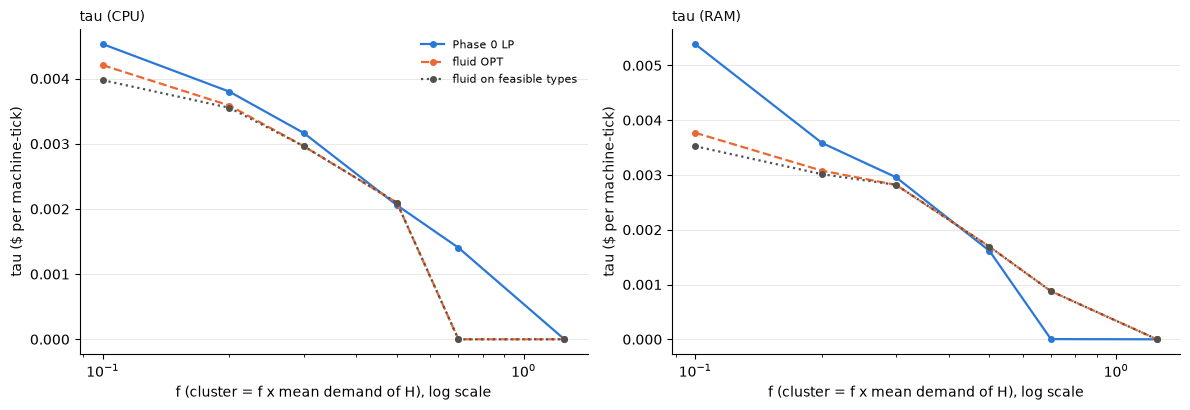

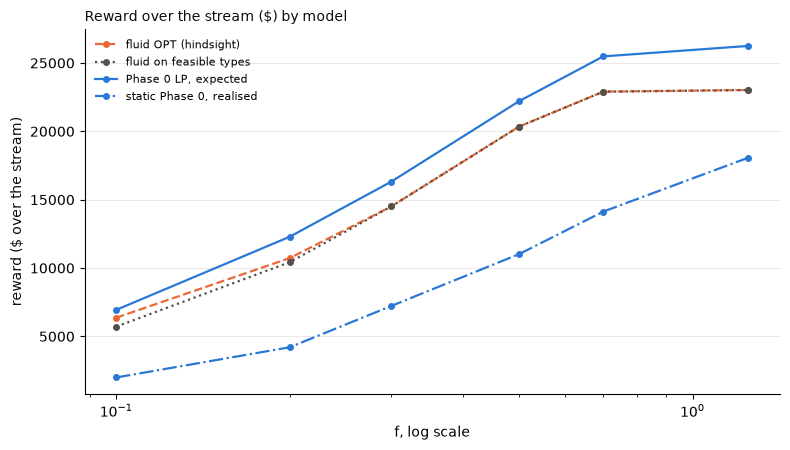

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
te.fig_tau_vs_f(R, axs)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.6))
te.fig_reward_vs_f(R, ax)
plt.tight_layout(); plt.show()

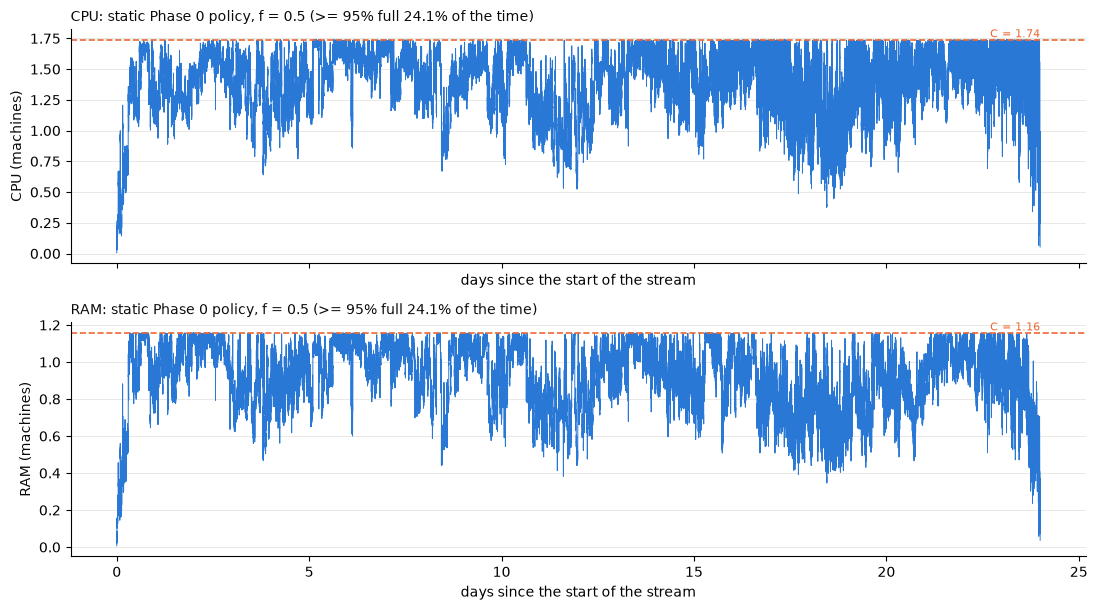

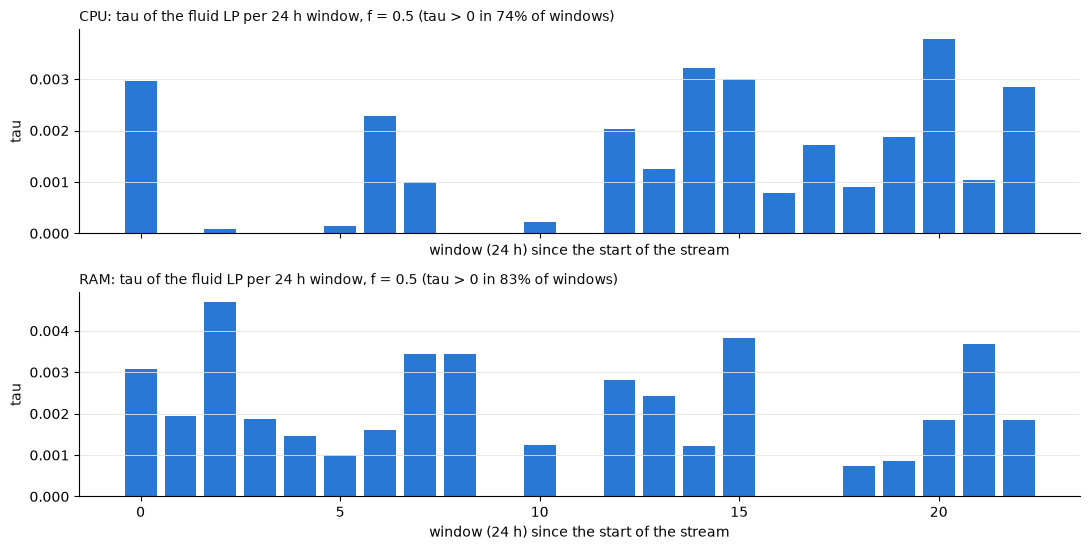

In [10]:
rs = next(r for r in R if r["f"] == f_sel)
fig, axs = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)
te.fig_occupancy(rs, axs, cfg.time.tick_seconds)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
te.fig_tau_windows(rs, axs, 24)
plt.tight_layout(); plt.show()

## 4. Unseen types, H vs stream, bucketed MILP on one week

Read from the cache of `scripts/week32/theory_models_2.py` (`reports/week32/theory_models_2_cache.pkl`): the
bucketed MILP alone takes about 15 minutes per f. Run that script first.

In [11]:
import pickle
with open(ROOT / "reports" / "week32" / "theory_models_2_cache.pkl", "rb") as fh:
    C2 = pickle.load(fh)
print("static Phase 0 policy: unseen types rejected vs dual rule")
display(C2["n1"])
print("f selected by the fixed rule (closest to 20-30%, ties to 25%):", C2["sel"])

static Phase 0 policy: unseen types rejected vs dual rule


,f,unseen types,% time >= 95% full (CPU or RAM),"mean occupancy / C (CPU, RAM)",% jobs rejected for lack of space,jobs admitted,unseen-type jobs admitted,realised reward $,split CV / profit / carbon $,static / fluid OPT
0,0.10,reject,1.4%,"28.6%, 20.2%",0.09%,"10,561",0,"1,107.8","1,632 / 160 / -684",17.4%
1,0.10,dual_rule,26.0%,"79.9%, 72.0%",1.47%,"9,246","1,410","1,994.7","3,486 / 431 / -1,922",31.3%
2,0.20,reject,1.4%,"40.1%, 35.7%",0.48%,"66,397",0,"3,249.7","4,658 / 495 / -1,903",30.3%
3,0.20,dual_rule,28.0%,"79.2%, 76.2%",4.03%,"59,796","1,686","4,203.7","7,078 / 884 / -3,758",39.2%
4,0.30,reject,4.0%,"48.7%, 45.9%",0.89%,"102,801",0,"5,635.9","8,313 / 831 / -3,507",38.9%
5,0.30,dual_rule,25.9%,"80.8%, 78.0%",4.38%,"96,408","1,871","7,222.9","11,576 / 1,436 / -5,789",49.8%
6,0.50,reject,4.8%,"55.0%, 54.7%",1.18%,"171,133",0,"10,105.1","15,323 / 1,403 / -6,621",49.7%
7,0.50,dual_rule,24.1%,"79.3%, 78.9%",4.97%,"164,104","2,092","11,016.9","18,642 / 1,828 / -9,453",54.1%
8,0.70,reject,4.9%,"52.8%, 53.1%",1.06%,"201,087",0,"11,970.5","19,220 / 1,623 / -8,872",52.3%
9,0.70,dual_rule,16.3%,"75.8%, 75.5%",3.21%,"198,373","2,395","14,127.6","24,298 / 2,428 / -12,599",61.7%


f selected by the fixed rule (closest to 20-30%, ties to 25%): {'reject': 0.7, 'dual_rule': 0.5}


In [12]:
print("H vs stream (types seen in both, weighted by H's rate):",
      {k: round(C2["hv"][k], 4) for k in ("lambda_ratio", "rd_ratio", "r_tilde_ratio", "load_H", "load_stream",
                                          "load_stream_unseen")})
display(C2["top"])
display(C2["n4"])
display(C2["n5"])
if "n6" in C2:
    print("one day (end-of-window effect: the MILP can exceed the fluid LP, see theory_models_2.md)")
    display(C2["n6"])

H vs stream (types seen in both, weighted by H's rate): {'lambda_ratio': 1.5331, 'rd_ratio': 1.0344, 'r_tilde_ratio': 0.6239, 'load_H': 3.4741, 'load_stream': 3.2187, 'load_stream_unseen': 1.3466}


,type,lambda H /h,lambda stream /h,mean r*d H,mean r*d stream,load H,load stream,load gap,bid bin,priority,hw profile
3723,20418,0.01191,0.001736,15.61,16.74,0.1859,0.02907,-0.1568,128,4.0,2
3715,19074,0.01191,0.005209,12.5,9.687,0.1488,0.05046,-0.09839,120,2.0,2
3711,18511,0.02381,0.001736,3.771,2.247,0.0898,0.003901,-0.0859,116,4.0,15
3714,18832,0.01786,0.006946,6.034,4.141,0.1077,0.02876,-0.07898,118,4.0,16
3720,19618,0.005953,0.001736,15.43,11.28,0.09186,0.01958,-0.07227,123,4.0,2
3721,19714,0.005953,0.001736,15.36,13.02,0.09144,0.02261,-0.06883,124,2.0,2
3722,19778,0.005953,0.005209,15.9,10.28,0.09466,0.05354,-0.04112,124,4.0,2
3718,19298,0.005953,0.001736,9.002,8.246,0.05359,0.01432,-0.03927,121,4.0,2
3713,18818,0.005953,0.001736,6.876,5.058,0.04093,0.008783,-0.03215,118,4.0,2
3708,18191,0.01191,0.003473,3.389,2.644,0.04034,0.009184,-0.03116,114,4.0,15


,f,Phase 0 LP expected $,"LP on stream statistics, Phase 0 grid $",Phase 0 x on stream statistics $,fluid OPT (refit grid) $
0,0.3,"16,315.9","14,625.1","6,672.6","14,501.5"
1,0.5,"22,204.0","20,380.1","10,446.4","20,346.2"
2,0.7,"25,481.9","22,836.9","13,227.5","22,901.2"


,f,jobs in the window,MILP candidates / nonzeros,fluid OPT $,fluid feasible $,bucketed MILP (type rewards) $,bucketed MILP realised (job rewards) $,discretization cost $,discretization cost %,fluid >= feasible >= MILP,"MILP status, gap",MILP runtime s,LPs runtime s,true-duration feasible,MILP LP-relaxation bound $,cost range (LP bound .. incumbent) $
0,0.3,"59,985","53,214 / 9,266,342","4,491.03","4,491.03","3,619.86","3,754.51",871.17,19.40%,True,Time limit reached. (HiGHS Status 13: Time lim...,562,0.1,True,"4,226.07",264.96 .. 871.17
1,0.5,"59,985","53,214 / 9,266,342","6,175.83","6,175.83","5,271.86","5,360.98",903.97,14.64%,True,Time limit reached. (HiGHS Status 13: Time lim...,561,0.1,True,"5,659.51",516.32 .. 903.97
2,0.7,"59,985","53,214 / 9,266,342","6,867.87","6,867.87","6,353.44","6,395.09",514.43,7.49%,True,Time limit reached. (HiGHS Status 13: Time lim...,561,0.1,True,"6,412.64",455.22 .. 514.43


one day (end-of-window effect: the MILP can exceed the fluid LP, see theory_models_2.md)


,f,jobs in the window,MILP candidates / nonzeros,fluid OPT $,fluid feasible $,bucketed MILP (type rewards) $,bucketed MILP realised (job rewards) $,discretization cost $,discretization cost %,fluid >= feasible >= MILP,"MILP status, gap",MILP runtime s,MILP LP-relaxation bound $,cost range (LP bound .. incumbent) $
0,0.3,"8,003","6,974 / 1,020,170",916.20,916.20,"1,096.44","1,098.60",-180.24,-19.67%,False,Time limit reached. (HiGHS Status 13: Time lim...,900,"1,109.95",-193.75 .. -180.24
1,0.5,"8,003","6,974 / 1,020,170","1,297.59","1,297.59","1,454.58","1,456.09",-156.98,-12.10%,False,Time limit reached. (HiGHS Status 13: Time lim...,900,"1,467.90",-170.31 .. -156.98
2,0.7,"8,003","6,974 / 1,020,170","1,555.17","1,555.17","1,658.02","1,658.99",-102.85,-6.61%,False,Time limit reached. (HiGHS Status 13: Time lim...,900,"1,663.18",-108.01 .. -102.85


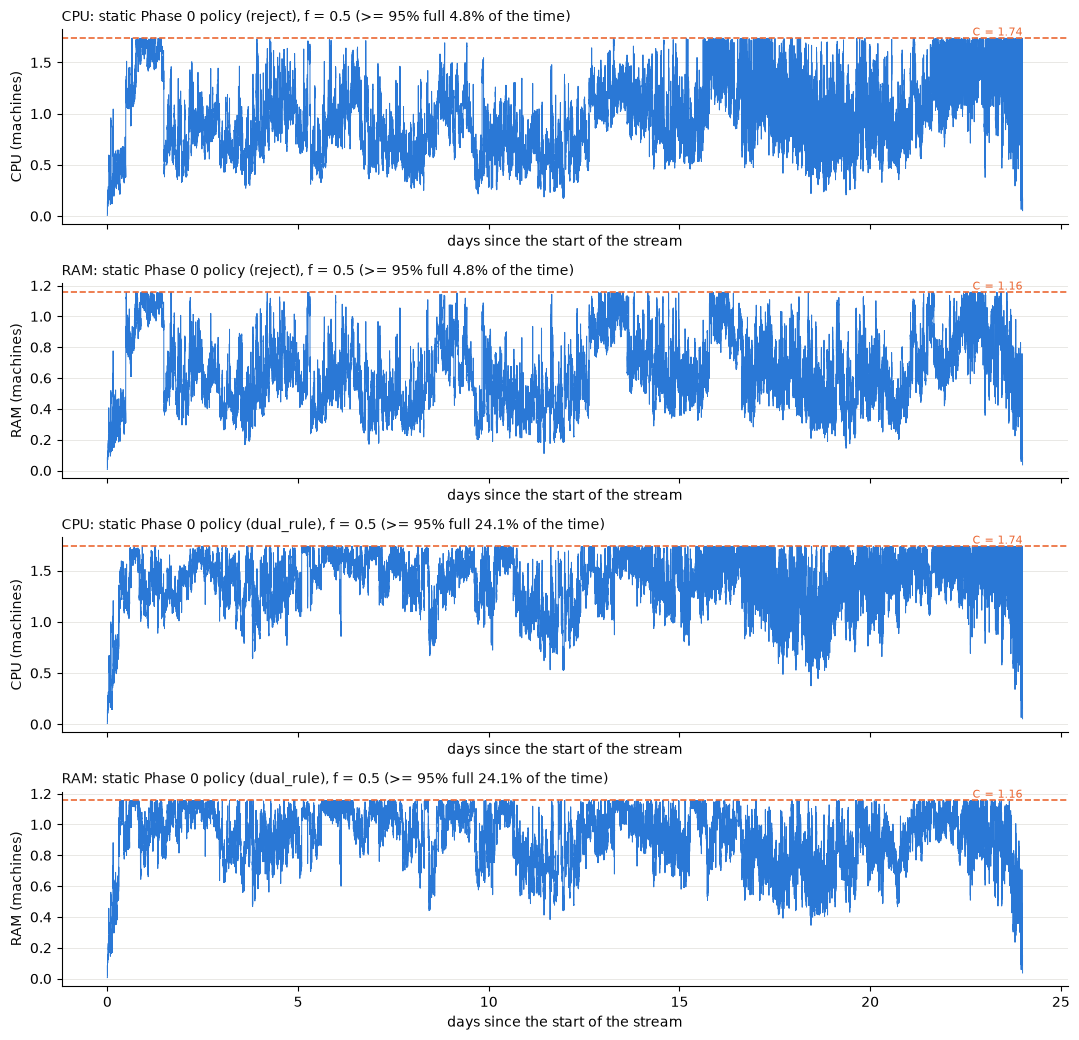

In [13]:
rs = C2["selected"]
fig, axs = plt.subplots(4, 1, figsize=(11, 10.5), sharex=True)
te.fig_occupancy(rs, axs[:2], cfg.time.tick_seconds, option="reject")
te.fig_occupancy(rs, axs[2:], cfg.time.tick_seconds, option="dual_rule")
plt.tight_layout(); plt.show()